# Can a published weight edit be found from the weights alone?

**Question.** Someone publishes model weights with a small edit. Without the original weights, can we tell that a layer was edited, and which neurons?

**Test case.** The 50-pass edit from *Sparks of Weight-Space Programming*, applied to `Qwen/Qwen3.5-0.8B`.

**Why it matters for Swedish models.** SE.LLMA builds on third-party weights, and this edit raises loss on Swedish text (section 7).

**Labels.** *Prospective*: first look, rules fixed beforehand. *Retrospective*: already seen during exploration.

All logic is in the `wsp` package; this notebook only calls it. CPU only.

In [1]:
from IPython.display import Image

from wsp import detect, io, loss, plots, weights

DEV_LAYERS = (2, 6, 10, 13, 17, 21)        # clean layers used to set the alarm thresholds
TEST_LAYERS = (0, 3, 7, 11, 14, 18, 22)    # layers held out for synthetic edits
SIZES = (0.03, 0.05, 0.09)                 # edit size as a share of the layer's weight norm
DECISION_SIZE = 0.09                       # the size the claims are judged at
KINDS = ("svd", "random")                  # a direction the layer already uses, or a random one
TEST_SEEDS = (100, 101)
RANDOM_SEEDS = (0, 1, 2)

## 1. What the published edit is *(retrospective)*

Rebuilt from the released patch. The code stops if any tensor's hash differs from the release.

In [2]:
edit = weights.load_published_edit()
description = {L: weights.describe_edit(base, edited) for L, (base, edited) in edit.items()}
io.save_json(io.RESULTS / "edit_description.json", {str(L): d for L, d in description.items()})
plots.table([{"layer": L, "neurons changed": len(d["columns"]), "share of layer norm": d["rel_change"],
              "rank-one share": d["rank1_share"], "multiplier": d["multiplier"]}
             for L, d in description.items()], digits=4)

| layer | neurons changed | share of layer norm | rank-one share | multiplier |
|---|---|---|---|---|
| 15 | 64 | 0.1064 | 1.0000 | 6.0003 |
| 19 | 64 | 0.0811 | 1.0000 | 6.0002 |

**Reading.** One direction per layer, on 64 of 3,584 neurons. The multiplier is 6, not 1: each neuron's loading on the direction is reversed and made five times larger (`w' = w − 6u(u·w)`). The article says the direction was "subtracted"; it was subtracted six times over, so it is over-corrected, not removed.

## 2. Detectors and decision rules

Both detectors read one checkpoint's weights. Neither sees the original or the true edited neurons.

- **Spectral.** Take the singular vectors of a layer's MLP output matrix. A change confined to a few neurons shows up as a vector that sits on those neurons. The statistic is how concentrated the most concentrated of the top 16 vectors is; the detector names that vector's 64 largest neurons.
- **Balance** (the alternative method). In trained weights a neuron's output norm tracks its input norms. The statistic is how far the 64 worst neurons depart from that relation.

| | A. Screening: is there an edit? | B. Localisation: where, given a suspect layer? |
|---|---|---|
| Rule | A layer alarms if its statistic exceeds the highest statistic among the six clean development layers | The detector names 64 neurons |
| Tested on | 28 held-out synthetic edits at size 0.09; false alarms counted on the 18 other clean layers | The same 28 edits |
| Supported | Recall ≥ 0.80 and at most 1 false alarm | Mean precision ≥ 0.80 |
| Challenged | Recall < 0.50, or more than 1 false alarm | Mean precision < 0.50 |

**Known before the held-out run** (from exploration):
- The spectral threshold is 255.9; the published edit scored 125.8 and 137.8. Claim A was expected to fail for the spectral detector.
- On the published edit, spectral precision was 0.92 in both layers; balance precision was 0.25 and 0.12.
- The layer lists were fixed before any clean statistic was computed.

## 3. Clean model: how suspicious do untouched layers look? *(retrospective)*

In [3]:
mlps = weights.load_mlps()
clean = {d: detect.screen(mlps, d) for d in detect.DETECTORS}            # about 1 minute
thresholds = {d: detect.calibrate(clean[d], DEV_LAYERS) for d in detect.DETECTORS}
io.save_json(io.RESULTS / "clean_screen.json", {
    "dev_layers": DEV_LAYERS, "test_layers": TEST_LAYERS, "thresholds": thresholds,
    "rows": {d: [{"layer": r["layer"], "stat": r["stat"]} for r in clean[d]] for d in detect.DETECTORS}})
plots.table([{"layer": s["layer"],
              "set": "development" if s["layer"] in DEV_LAYERS else "test" if s["layer"] in TEST_LAYERS else "other",
              "spectral": s["stat"], "neurons the vector sits on": s["effective_neurons"], "balance": b["stat"]}
             for s, b in zip(clean["spectral"], clean["balance"])], digits=1)

| layer | set | spectral | neurons the vector sits on | balance |
|---|---|---|---|---|
| 0 | test | 9.6 | 372.7 | 7.6 |
| 1 | other | 7.7 | 464.8 | 9.5 |
| 2 | development | 18.1 | 198.2 | 8.7 |
| 3 | test | 10.4 | 344.9 | 6.1 |
| 4 | other | 10.7 | 334.6 | 8.0 |
| 5 | other | 9.2 | 389.4 | 8.6 |
| 6 | development | 200.3 | 17.9 | 7.2 |
| 7 | test | 8.8 | 405.7 | 5.4 |
| 8 | other | 25.0 | 143.2 | 5.5 |
| 9 | other | 12.7 | 282.7 | 5.0 |
| 10 | development | 255.9 | 14.0 | 5.5 |
| 11 | test | 81.2 | 44.1 | 4.4 |
| 12 | other | 9.2 | 389.0 | 4.9 |
| 13 | development | 23.1 | 155.4 | 5.0 |
| 14 | test | 43.4 | 82.5 | 3.8 |
| 15 | other | 43.5 | 82.3 | 4.7 |
| 16 | other | 14.2 | 253.0 | 5.6 |
| 17 | development | 20.8 | 172.2 | 5.0 |
| 18 | test | 22.8 | 157.3 | 4.3 |
| 19 | other | 18.9 | 189.9 | 7.0 |
| 20 | other | 12.4 | 288.0 | 7.4 |
| 21 | development | 8.3 | 429.7 | 6.7 |
| 22 | test | 26.9 | 133.3 | 5.1 |
| 23 | other | 35.0 | 102.5 | 3.3 |

In [4]:
thresholds

{'spectral': 255.94284057617188, 'balance': 8.708314895629883}

**Reading.** Thresholds: 255.9 (spectral) and 8.7 (balance). Untouched layers 10 and 6 each have a top singular vector sitting on about 14 and 18 neurons, so clean weights already contain the pattern the spectral detector looks for. No other clean layer exceeds 82.

## 4. Held-out synthetic edits *(prospective)*

84 new edits of the published kind (one direction pushed out of 64 neurons), one at a time in the seven test layers, at three sizes. No edit had been tried in these layers before; their clean statistics had been seen. Each is generated once and scored by both detectors.

In [5]:
sweep_rows = detect.sweep(mlps, clean, TEST_LAYERS, SIZES, KINDS, TEST_SEEDS)     # about 5 minutes
summary = detect.summarise(sweep_rows, clean, thresholds, DEV_LAYERS)
io.save_json(io.RESULTS / "synthetic_sweep.json", {"summary": summary, "rows": sweep_rows})
plots.table(summary, ["detector", "size", "n", "recall", "false_alarms", "mean_precision_at_64",
                      "median_rank", "auroc_vs_clean"])

| detector | size | n | recall | false_alarms | mean_precision_at_64 | median_rank | auroc_vs_clean |
|---|---|---|---|---|---|---|---|
| balance | 0.030 | 28 | 0.000 | 1 | 0.011 | 15.000 | 0.395 |
| balance | 0.050 | 28 | 0.000 | 1 | 0.016 | 15.000 | 0.385 |
| balance | 0.090 | 28 | 0.107 | 1 | 0.177 | 18.000 | 0.411 |
| spectral | 0.030 | 28 | 0.000 | 0 | 0.069 | 10.000 | 0.538 |
| spectral | 0.050 | 28 | 0.000 | 0 | 0.106 | 12.500 | 0.526 |
| spectral | 0.090 | 28 | 0.000 | 0 | 0.767 | 4.000 | 0.772 |

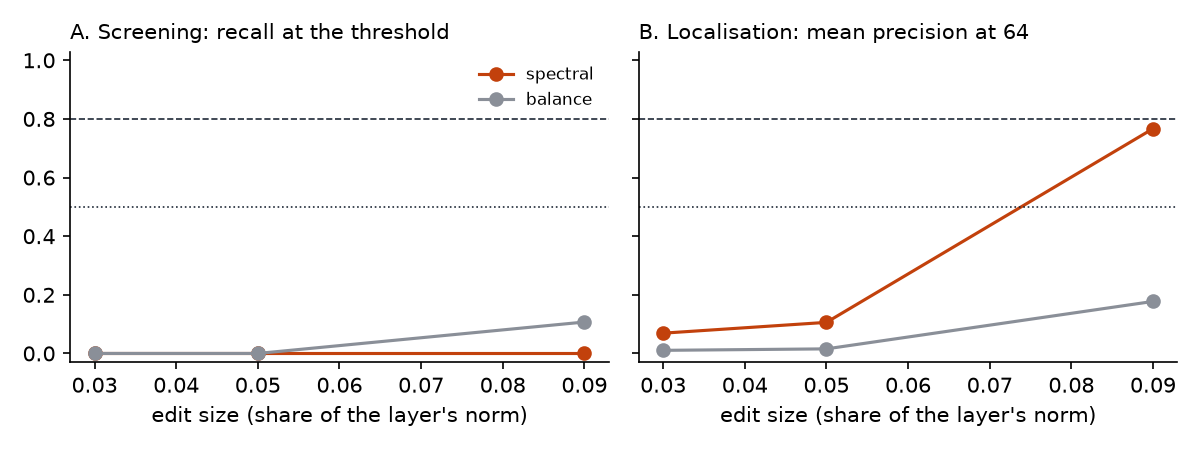

In [6]:
Image(filename=plots.sweep_figure(summary, io.RESULTS / "fig_sweep.png"))

Per test layer, spectral detector at the decision size:

In [7]:
plots.table(detect.summarise_by_layer(sweep_rows, clean, "spectral", DECISION_SIZE), digits=2)

| layer | clean_stat | n | mean_stat | mean_precision_at_64 | median_rank |
|---|---|---|---|---|---|
| 0 | 9.62 | 4 | 33.30 | 0.78 | 5.00 |
| 3 | 10.39 | 4 | 30.40 | 0.76 | 6.50 |
| 7 | 8.83 | 4 | 27.99 | 0.52 | 11.50 |
| 11 | 81.21 | 4 | 55.46 | 0.39 | 3.00 |
| 14 | 43.42 | 4 | 39.59 | 0.91 | 4.50 |
| 18 | 22.79 | 4 | 37.81 | 1.00 | 5.50 |
| 22 | 26.88 | 4 | 39.71 | 1.00 | 5.00 |

**Reading, at the decision size 0.09 (28 edits).**

- **A, screening: challenged for both detectors.** No synthetic edit reached the spectral threshold (highest 81.3 against 255.9). The balance detector caught 3 of 28, with 1 false alarm. Threshold-free, the spectral detector puts the edited layer at a median rank of 4 of 24.
- **B, localisation: inconclusive for spectral (0.77 against a bar of 0.80), challenged for balance (0.18).** Spectral reaches precision of 0.80 or more in 19 of 28 edits (all 64 neurons in 17) and falls below 0.10 in 4. It is reliable when the edit uses a random direction (0.95) and unreliable when it uses a direction the layer already has (0.58). It is weakest in layer 11, whose clean weights already hold a localised vector.
- **Smaller edits never alarm and are rarely localised.** At 5% and 3% of the layer's norm, mean spectral precision is 0.11 and 0.07. One 5% edit of 28 was localised fully; no 3% edit was.

## 5. The published edit and three random edits *(retrospective)*

The random edits change the same 64 neurons by the same amount, along a random direction.

In [8]:
variants = {"published": {L: edited for L, (base, edited) in edit.items()}}
variants.update({f"random{s}": weights.random_matched_edit(edit, s) for s in RANDOM_SEEDS})
published_rows = [{"edit": name, **row} for name, e in variants.items()
                  for row in detect.score_checkpoint(mlps, clean, thresholds, e)]
io.save_json(io.RESULTS / "published.json", published_rows)
plots.table(published_rows, ["edit", "detector", "layer", "stat", "clean_stat", "alarm", "rank",
                             "precision_at_64", "direction_cosine"])

| edit | detector | layer | stat | clean_stat | alarm | rank | precision_at_64 | direction_cosine |
|---|---|---|---|---|---|---|---|---|
| published | spectral | 15 | 125.801 | 43.543 | False | 4 | 0.922 | 0.939 |
| published | spectral | 19 | 137.842 | 18.874 | False | 3 | 0.922 | 0.945 |
| published | balance | 15 | 5.068 | 4.731 | False | 16 | 0.250 | – |
| published | balance | 19 | 7.173 | 6.955 | False | 8 | 0.125 | – |
| random0 | spectral | 15 | 125.553 | 43.543 | False | 4 | 1.000 | 0.980 |
| random0 | spectral | 19 | 185.542 | 18.874 | False | 3 | 0.984 | 0.944 |
| random0 | balance | 15 | 5.405 | 4.731 | False | 15 | 0.312 | – |
| random0 | balance | 19 | 7.389 | 6.955 | False | 6 | 0.188 | – |
| random1 | spectral | 15 | 126.100 | 43.543 | False | 4 | 1.000 | 0.982 |
| random1 | spectral | 19 | 181.803 | 18.874 | False | 3 | 0.984 | 0.973 |
| random1 | balance | 15 | 5.418 | 4.731 | False | 15 | 0.312 | – |
| random1 | balance | 19 | 7.371 | 6.955 | False | 6 | 0.188 | – |
| random2 | spectral | 15 | 124.185 | 43.543 | False | 4 | 0.969 | 0.983 |
| random2 | spectral | 19 | 171.213 | 18.874 | False | 3 | 0.969 | 0.957 |
| random2 | balance | 15 | 5.399 | 4.731 | False | 15 | 0.297 | – |
| random2 | balance | 19 | 7.340 | 6.955 | False | 7 | 0.156 | – |

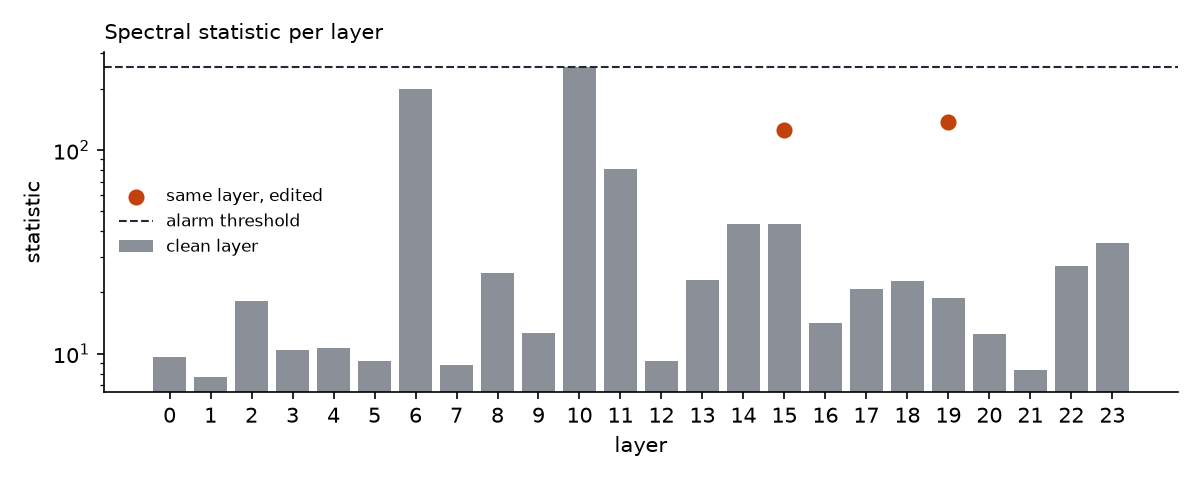

In [9]:
spectral_published = [r for r in published_rows if r["edit"] == "published" and r["detector"] == "spectral"]
Image(filename=plots.screen_figure(clean["spectral"], spectral_published, thresholds["spectral"],
                                   io.RESULTS / "fig_screen.png"))

**Reading.** This reproduces exploration. The spectral detector names 59 of the 64 edited neurons in each layer and recovers the direction (cosine 0.94 and 0.95). But the two layers rank 4th and 3rd, below clean layers 10 and 6, and neither alarms. Random edits on the same neurons are found just as well, so the detector responds to the shape and size of a change, not its meaning. The balance detector ranks the edited layers 16th and 8th.

## 6. Examples *(retrospective)*

Layer 15: the 64 neurons the spectral detector named against the 64 truly edited.

In [10]:
detect.compare_neurons(spectral_published[0]["neurons"], description[15]["columns"])

{'recovered': 59,
 'missed': [34, 39, 100, 156, 328],
 'wrongly_named': [235, 672, 1074, 1081, 1171]}

The five most suspicious layers of the published checkpoint:

In [11]:
plots.table(detect.shortlist(clean["spectral"], spectral_published), digits=1)

| rank | layer | stat | edited | effective_neurons |
|---|---|---|---|---|
| 1 | 10 | 255.9 | False | 14.0 |
| 2 | 6 | 200.3 | False | 17.9 |
| 3 | 19 | 137.8 | True | 26.0 |
| 4 | 15 | 125.8 | True | 28.5 |
| 5 | 11 | 81.2 | False | 44.1 |

**Reading.** Someone working down this shortlist inspects two clean layers before reaching an edited one. Weights alone show *where* a change of this kind sits. They do not show *that* a checkpoint was changed.

## 7. Why it matters: loss on Swedish and English text

Next-token loss on fixed passages, base model against the published edit and the three random edits. No text is generated.
The development passages were scored in exploration *(retrospective)*; the test split is scored here *(prospective)*.
The Swedish passages are 1970s prose and the English ones are maths questions, so the two are **not** matched: this does not show the edit is specific to Swedish.

In [12]:
loss_rows = {split: loss.run_loss(split) for split in ("dev", "test")}       # cached; about 25 minutes on a first run
changes = [{"split": split, "lang": lang, "edit": c, **loss.paired_change(rows, c, lang)}
           for split, rows in loss_rows.items()
           for lang in ("sv", "en") if any(r["lang"] == lang for r in rows)
           for c in ("published", "random0", "random1", "random2")]
io.save_json(io.RESULTS / "loss_summary.json", changes)
plots.table(changes, digits=4)

| split | lang | edit | mean | ci_low | ci_high | n | worse |
|---|---|---|---|---|---|---|---|
| dev | sv | published | 0.0446 | 0.0402 | 0.0484 | 20 | 20 |
| dev | sv | random0 | 0.0312 | 0.0278 | 0.0362 | 20 | 20 |
| dev | sv | random1 | 0.0132 | 0.0107 | 0.0152 | 20 | 19 |
| dev | sv | random2 | 0.0060 | 0.0034 | 0.0076 | 20 | 16 |
| test | sv | published | 0.0523 | 0.0461 | 0.0593 | 84 | 84 |
| test | sv | random0 | 0.0325 | 0.0277 | 0.0371 | 84 | 83 |
| test | sv | random1 | 0.0203 | 0.0166 | 0.0253 | 84 | 74 |
| test | sv | random2 | 0.0089 | 0.0073 | 0.0105 | 84 | 73 |
| test | en | published | 0.0067 | -0.0002 | 0.0137 | 32 | 20 |
| test | en | random0 | 0.0019 | -0.0016 | 0.0053 | 32 | 17 |
| test | en | random1 | 0.0074 | 0.0038 | 0.0112 | 32 | 24 |
| test | en | random2 | 0.0041 | 0.0012 | 0.0070 | 32 | 23 |

The two Swedish test passages whose loss rose most under the published edit:

In [13]:
plots.table(loss.worst_passages(loss_rows["test"], loss.load_passages("test"), "published", "sv"), digits=3)

| id | change | text |
|---|---|---|
| sv_P416_3 | 0.107 | I dagens samhälle premieras emellertid på flera olika sätt sammanboende i förhållande till gifta. Även om detta inte sker enligt lagens bokstav är det ett faktum. En ensamstående moder har betydligt lättare att få in sitt barn på daghem (även om hon i verkligheten sammanbor med barnets far). En stud |
| sv_P108_6 | 0.097 | På grundval av den pensionsgrundande inkomsten beräknas pensionspoäng, som registreras på Ert poängkort hos försäkringskassan. På slutskattesedeln finns den pensionsgrundande inkomsten angiven. Vill man räkna ut poängen kan man göra detta genom att dela den pensionsgrundande inkomsten för ett visst  |

**Reading.** On held-out Swedish text the published edit raises loss by 0.052 nats per token (95% interval 0.046 to 0.059), on all 84 passages. The development figure was 0.045. Random edits of the same size on the same neurons cost 0.009 to 0.032, so part of the cost comes from disturbing those neurons at all. On the English questions the published edit (+0.007) is within the range of the random edits.

## 8. Verdicts

In [14]:
verdicts = {s["detector"]: detect.verdict(s) for s in summary if s["size"] == DECISION_SIZE}
io.save_json(io.RESULTS / "verdicts.json", verdicts)
verdicts

{'balance': {'screening': 'challenged', 'localisation': 'challenged'},
 'spectral': {'screening': 'challenged', 'localisation': 'inconclusive'}}

- **Screening (is there an edit?): challenged for both detectors.** Clean layers already look more "edited" than the edit does.
- **Localisation (where is it?): inconclusive for spectral** (0.77 against a bar of 0.80), **challenged for balance.**
- **In short:** weights alone often show where a 9% edit sits, not whether one exists, and smaller edits are rarely found.

**Limits.** One model. One published edit, in two layers. Synthetic edits of one family. The threshold needs known-clean weights to calibrate. The Swedish and English passages are not matched.

**Next experiment.** Build an edit that lowers Swedish quality but not English, at several sizes, and find whether the damage appears below the size at which the detector sees anything.